In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

df = pd.read_csv("data/iris/Iris.csv")
df.columns = df.columns.str.strip().str.lower()
df = df.drop(columns=["id"], errors="ignore")

df = df.rename(columns={
    "sepallengthcm": "sepal_length",
    "sepalwidthcm": "sepal_width",
    "petallengthcm": "petal_length",
    "petalwidthcm": "petal_width",
})
df["species"] = df["species"].str.replace("Iris-", "", regex=False)

print(df.shape)
print(df.head())

(150, 5)
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa


In [5]:
import os
print("Notebook run aagura folder:", os.getcwd())
print("Project folder la:", os.listdir("."))
print("data folder kulla:", os.listdir("data") if os.path.exists("data") else "data folder illa")


Notebook run aagura folder: D:\codeAlpha_irisflowerDetection
Project folder la: ['.git', '.gitattributes', '.gitignore', '.ipynb_checkpoints', 'data', 'iris_classification.ipynb', 'README.md', 'requirements.txt', 'venv']
data folder kulla: ['iris']


<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB
None
       sepal_length  sepal_width  petal_length  petal_width
count    150.000000   150.000000    150.000000   150.000000
mean       5.843333     3.054000      3.758667     1.198667
std        0.828066     0.433594      1.764420     0.763161
min        4.300000     2.000000      1.000000     0.100000
25%        5.100000     2.800000      1.600000     0.300000
50%        5.800000     3.000000      4.350000     1.300000
75%        6.400000     3.300000      5.100000     1.800000
max        7.900000     4.400000      6.900000     2.500000
species
setos

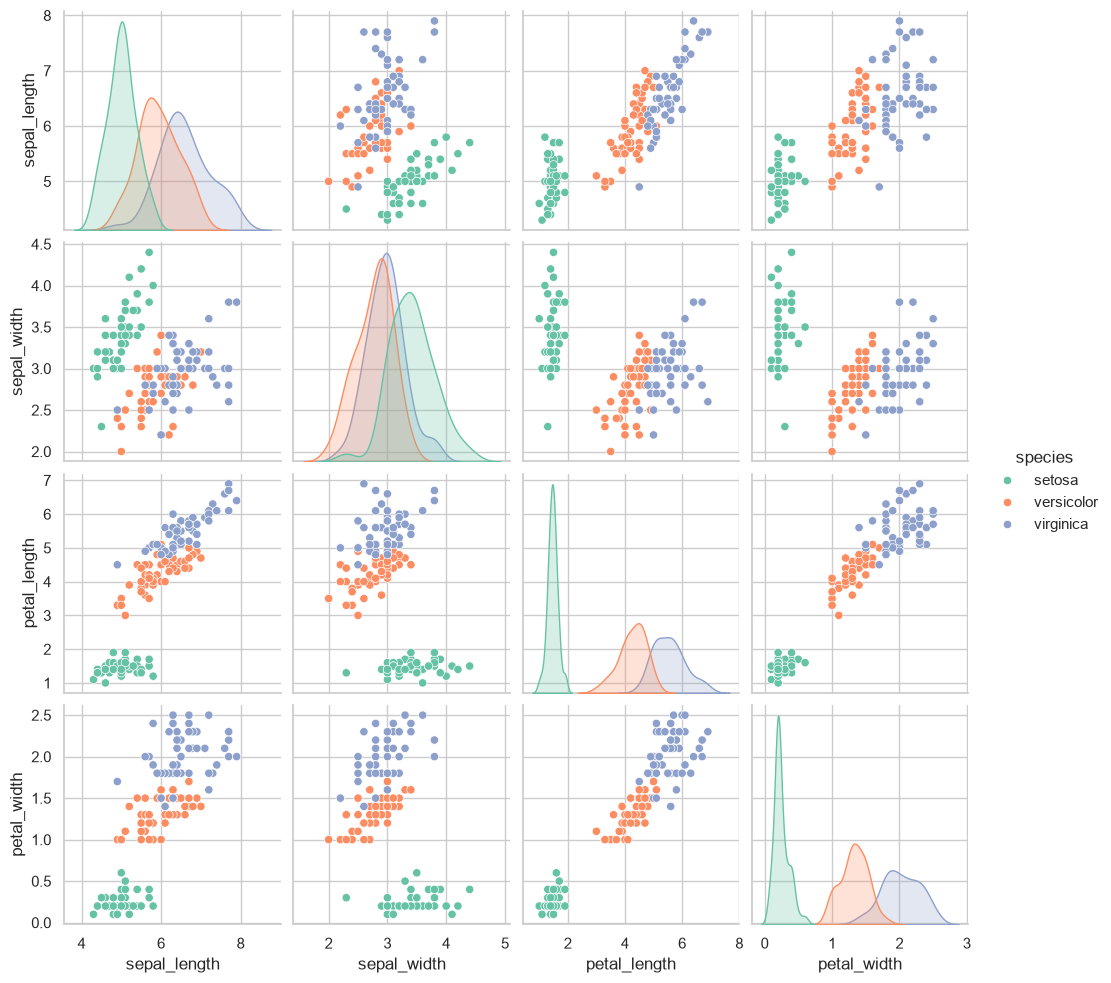

In [7]:
print(df.info())
print(df.describe())
print(df["species"].value_counts())
print("Missing values:", df.isnull().sum().sum())

sns.pairplot(df, hue="species", palette="Set2")
plt.show()

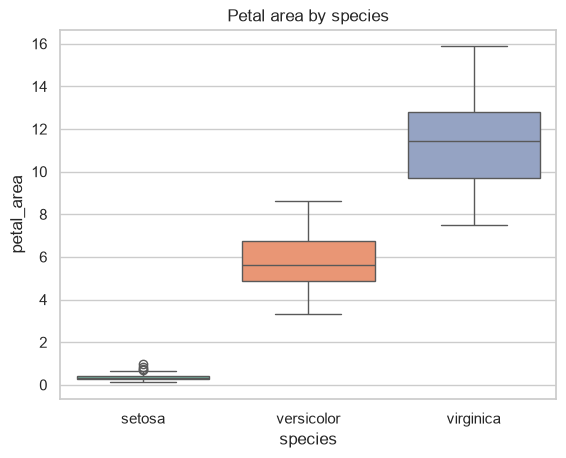

In [8]:
df["petal_area"] = df["petal_length"] * df["petal_width"]
df["sepal_area"] = df["sepal_length"] * df["sepal_width"]

base_features = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
extended_features = base_features + ["petal_area", "sepal_area"]

sns.boxplot(data=df, x="species", y="petal_area", palette="Set2")
plt.title("Petal area by species")
plt.show()

In [9]:
from sklearn.model_selection import train_test_split

X = df[extended_features]
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (120, 6) Test: (30, 6)


KNN                  0.958 (+/- 0.026)
Logistic Regression  0.958 (+/- 0.026)
Decision Tree        0.950 (+/- 0.017)
Random Forest        0.950 (+/- 0.031)
SVM                  0.967 (+/- 0.017)


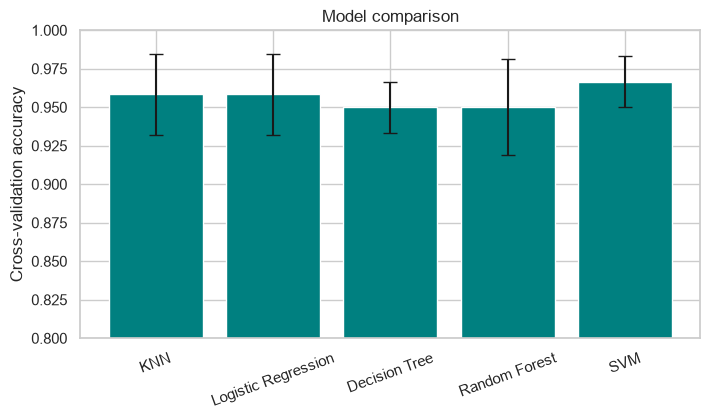

In [10]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

models = {
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=200)),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": make_pipeline(StandardScaler(), SVC()),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = {}
for name, model in models.items():
    scores = cross_val_score(model, X_train[base_features], y_train, cv=cv)
    results[name] = scores
    print(f"{name:20s} {scores.mean():.3f} (+/- {scores.std():.3f})")

plt.figure(figsize=(8, 4))
plt.bar(results.keys(), [s.mean() for s in results.values()],
        yerr=[s.std() for s in results.values()], color="teal", capsize=5)
plt.ylim(0.8, 1.0)
plt.ylabel("Cross-validation accuracy")
plt.title("Model comparison")
plt.xticks(rotation=20)
plt.show()

Base features (4):     0.950
Extended features (6): 0.950


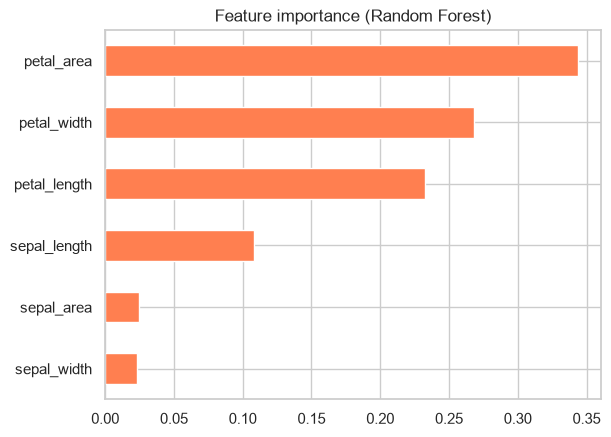

In [11]:
rf = RandomForestClassifier(random_state=42)

base_score = cross_val_score(rf, X_train[base_features], y_train, cv=cv).mean()
ext_score = cross_val_score(rf, X_train[extended_features], y_train, cv=cv).mean()

print(f"Base features (4):     {base_score:.3f}")
print(f"Extended features (6): {ext_score:.3f}")

rf.fit(X_train[extended_features], y_train)
importance = pd.Series(rf.feature_importances_, index=extended_features).sort_values()
importance.plot(kind="barh", color="coral", title="Feature importance (Random Forest)")
plt.show()

Best parameters: {'svc__C': 0.1, 'svc__gamma': 'scale', 'svc__kernel': 'linear'}
Best CV accuracy: 0.975

Test accuracy: 0.933
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



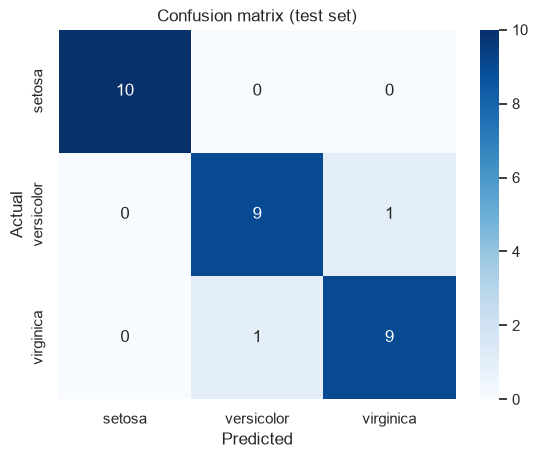

In [13]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(probability=True, random_state=42)),
])

param_grid = {
    "svc__C": [0.1, 1, 10, 100],
    "svc__kernel": ["linear", "rbf"],
    "svc__gamma": ["scale", 0.1, 0.01],
}

grid = GridSearchCV(pipe, param_grid, cv=cv, n_jobs=-1)
grid.fit(X_train[base_features], y_train)

best_model = grid.best_estimator_
print("Best parameters:", grid.best_params_)
print("Best CV accuracy:", round(grid.best_score_, 3))

y_pred = best_model.predict(X_test[base_features])
print("\nTest accuracy:", round(accuracy_score(y_test, y_pred), 3))
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred, labels=best_model.classes_)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=best_model.classes_, yticklabels=best_model.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix (test set)")
plt.show()

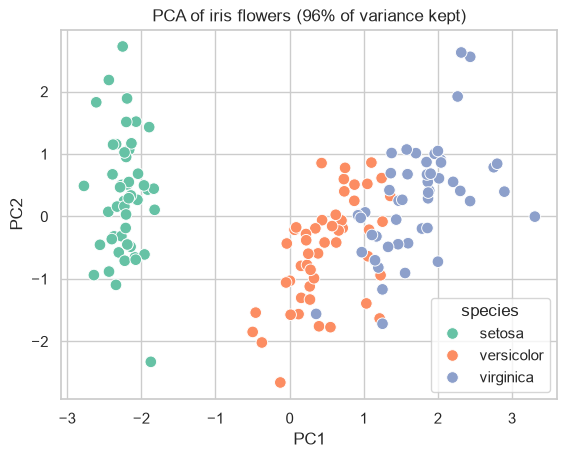

In [14]:
from sklearn.decomposition import PCA

scaled = StandardScaler().fit_transform(df[base_features])
pca = PCA(n_components=2)
points = pca.fit_transform(scaled)

plot_df = pd.DataFrame(points, columns=["PC1", "PC2"])
plot_df["species"] = df["species"].values

sns.scatterplot(data=plot_df, x="PC1", y="PC2", hue="species", palette="Set2", s=70)
plt.title(f"PCA of iris flowers ({pca.explained_variance_ratio_.sum():.0%} of variance kept)")
plt.show()

In [15]:
errors = X_test[base_features].copy()
errors["actual"] = y_test
errors["predicted"] = y_pred
wrong = errors[errors["actual"] != errors["predicted"]]

print(f"Misclassified: {len(wrong)} of {len(errors)}")
print(wrong if len(wrong) > 0 else "No mistakes on the test set!")

Misclassified: 2 of 30
     sepal_length  sepal_width  petal_length  petal_width      actual  \
134           6.1          2.6           5.6          1.4   virginica   
77            6.7          3.0           5.0          1.7  versicolor   

      predicted  
134  versicolor  
77    virginica  


In [16]:
def predict_flower(sepal_length, sepal_width, petal_length, petal_width):
    row = pd.DataFrame([[sepal_length, sepal_width, petal_length, petal_width]],
                       columns=base_features)
    probs = best_model.predict_proba(row)[0]
    best = best_model.classes_[probs.argmax()]
    print(f"Prediction: {best}  (confidence {probs.max():.1%})")
    for species, p in zip(best_model.classes_, probs):
        print(f"  {species:12s} {p:.1%}")

predict_flower(5.1, 3.5, 1.4, 0.2)   # should be setosa
predict_flower(6.0, 2.9, 4.5, 1.5)   # versicolor-like
predict_flower(6.7, 3.0, 5.8, 2.2)   # virginica-like

import joblib
joblib.dump(best_model, "iris_model.pkl")

Prediction: setosa  (confidence 97.4%)
  setosa       97.4%
  versicolor   1.6%
  virginica    1.0%
Prediction: versicolor  (confidence 85.2%)
  setosa       1.4%
  versicolor   85.2%
  virginica    13.5%
Prediction: virginica  (confidence 98.9%)
  setosa       0.5%
  versicolor   0.6%
  virginica    98.9%


['iris_model.pkl']

In [18]:
from sklearn.metrics import accuracy_score

best_cv_name = max(results, key=lambda k: results[k].mean())

print(f"- Best model in cross-validation: {best_cv_name} ({results[best_cv_name].mean():.1%} CV accuracy)")
print(f"- Final model: SVM tuned with GridSearchCV {grid.best_params_}")
print(f"- Test accuracy: {accuracy_score(y_test, y_pred):.1%}")
print(f"- Misclassified: {len(wrong)} of {len(errors)} test flowers")

- Best model in cross-validation: SVM (96.7% CV accuracy)
- Final model: SVM tuned with GridSearchCV {'svc__C': 0.1, 'svc__gamma': 'scale', 'svc__kernel': 'linear'}
- Test accuracy: 93.3%
- Misclassified: 2 of 30 test flowers


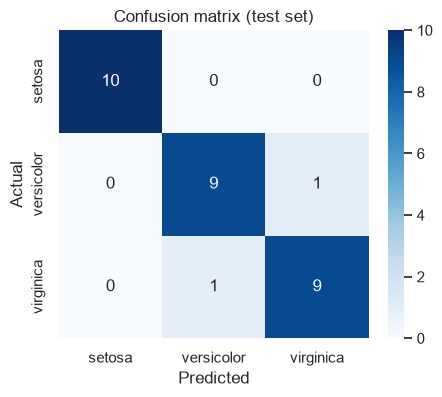

In [19]:
import os
os.makedirs("images", exist_ok=True)

cm = confusion_matrix(y_test, y_pred, labels=best_model.classes_)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=best_model.classes_, yticklabels=best_model.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix (test set)")
plt.savefig("images/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()